# Scale changes the evidence you see

**Objective:** Test systematic sampling sensitivity and distinguish data spacing, observation support and statistical independence.

Original project lesson. All observations are real USGS Landsat / U.S. Census inputs, with source details in `data/manifest.json`. No health outcome is inferred.

A source grid, an instrument footprint and a display tile are different objects. The source Landsat product is gridded at 30 m; this package selects native pixels at a larger systematic spacing. Adjacent thermal product pixels also share a coarser original measurement support.

Below, retaining every second or fourth table row is an inspectable sensitivity exercise on the existing sample. It is not a new full-resolution resampling procedure. Similar means do not prove absence of local features, bias or spatial dependence.

[Run this exact lesson in the browser Python Lab](https://jltobias.github.io/JupyterLite-OneHealth/lite/lab/index.html?path=06_spatial_scale.ipynb).

## Load the real bundled evidence

Run cells in order. In JupyterLite, the first run may download Python and Matplotlib and requires internet access. Wait for the kernel to finish. Files are in browser storage: use **File → Save and Export Notebook As** or right-click a file and **Download** to keep work outside this browser. Desktop execution uses the pinned build environment.

In [1]:
import sys, csv, json, math, statistics
from pathlib import Path
if sys.platform == "emscripten":
    import piplite
    await piplite.install("matplotlib")
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
manifest = json.loads(Path("data/manifest.json").read_text())
with Path("data/pixels.csv").open() as f:
    rows = list(csv.DictReader(f))
text_fields = {"id"}
data = [{k: (v if k in text_fields else float(v) if v else None)
         for k, v in row.items()} for row in rows]
tracts = json.loads(Path("data/tracts.geojson").read_text())["features"]
def values(key, source=data):
    return [r[key] for r in source if r[key] is not None and math.isfinite(r[key])]
def avg(key, source=data):
    a = values(key, source)
    return statistics.mean(a) if a else None
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
print(manifest["scene_id"], manifest["satellite_datetime"])
print("Real satellite samples:", len(data), "| population reference:", manifest["population_date"])


LC09_L2SP_042035_20240830_02_T1 2024-08-30T18:33:53.353894Z
Real satellite samples: 6890 | population reference: 2020-04-01


## Inspect the calculation

The following code keeps source units and dates explicit. Edit assumptions only after recording what changes.

In [2]:
steps = [1, 2, 4, 8]
summaries = [(step, len(data[::step]), avg("ndvi", data[::step]), avg("temperature_c", data[::step])) for step in steps]
for step,n,ndvi,temp in summaries:
    print(f"Every {step}th row: n={n}; NDVI={ndvi:.4f}; surface={temp:.2f} °C")

Every 1th row: n=6890; NDVI=0.3153; surface=43.57 °C
Every 2th row: n=3445; NDVI=0.3167; surface=43.56 °C
Every 4th row: n=1723; NDVI=0.3167; surface=43.55 °C
Every 8th row: n=862; NDVI=0.3162; surface=43.49 °C


## Make a figure from the observations

The figure describes the selected real evidence. It does not establish personal exposure or a causal health effect.

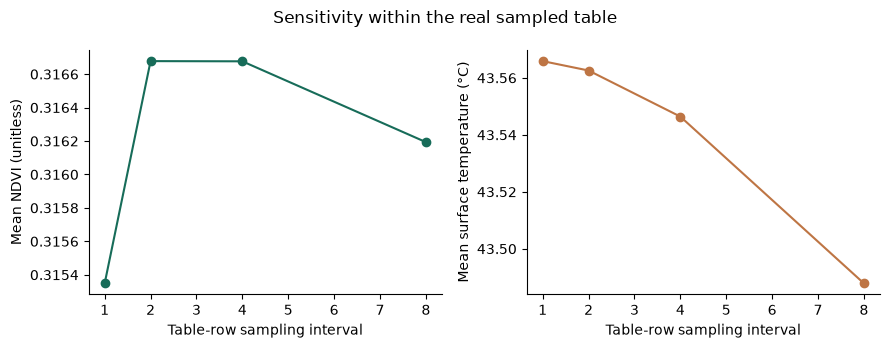

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].plot(steps, [s[2] for s in summaries], "o-", color="#176c59")
ax[0].set(xlabel="Table-row sampling interval", ylabel="Mean NDVI (unitless)")
ax[1].plot(steps, [s[3] for s in summaries], "o-", color="#be7544")
ax[1].set(xlabel="Table-row sampling interval", ylabel="Mean surface temperature (°C)")
fig.suptitle("Sensitivity within the real sampled table"); fig.tight_layout(); plt.show()

## Interpret and extend

Try different starting offsets with the same interval. Why can systematic spacing miss a narrow stream or street? Explain why treating every displayed tile as an independent thermal measurement would overstate the evidence.

## Sources and attribution

- [USGS EROS, Landsat Collection 2 Level-2 science products; dataset DOI 10.5066/P9OGBGM6](https://www.usgs.gov/landsat-missions/landsat-collection-2-level-2-science-products).
- [USGS, Landsat Collection 2 surface temperature](https://www.usgs.gov/landsat-missions/landsat-collection-2-surface-temperature).
- [U.S. Census Bureau, Census2020 TIGERweb Census Tracts layer 6 and POP100](https://tigerweb.geo.census.gov/arcgis/rest/services/Census2020/tigerWMS_Census2020/MapServer/6).

Data: USGS/NASA Landsat 8–9 Collection 2 Level-2, public domain; U.S. Census Bureau 2020 Census tracts and population, public domain. Accessed/acquired 7 November 2026. External readings are linked only; their prose, photographs, figures and code are not reproduced. Source organizations do not endorse this lesson.